In [4]:
%pip install japanize-matplotlib


[notice] A new release of pip is available: 25.3 -> 26.1.2
[notice] To update, run: python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


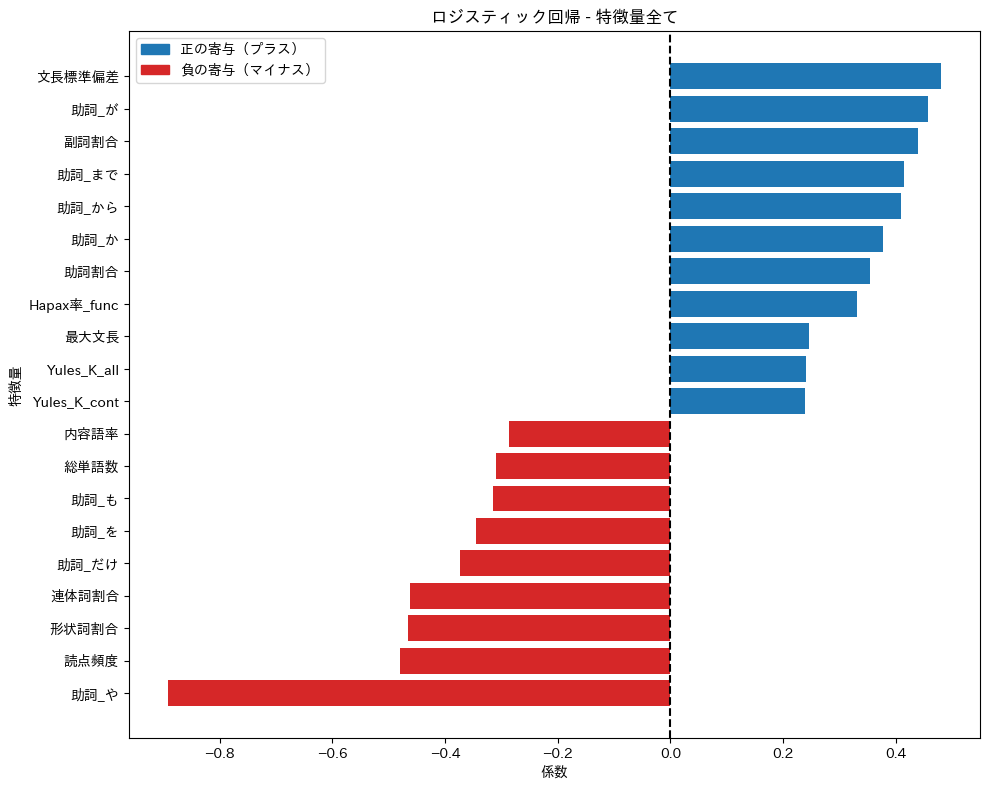

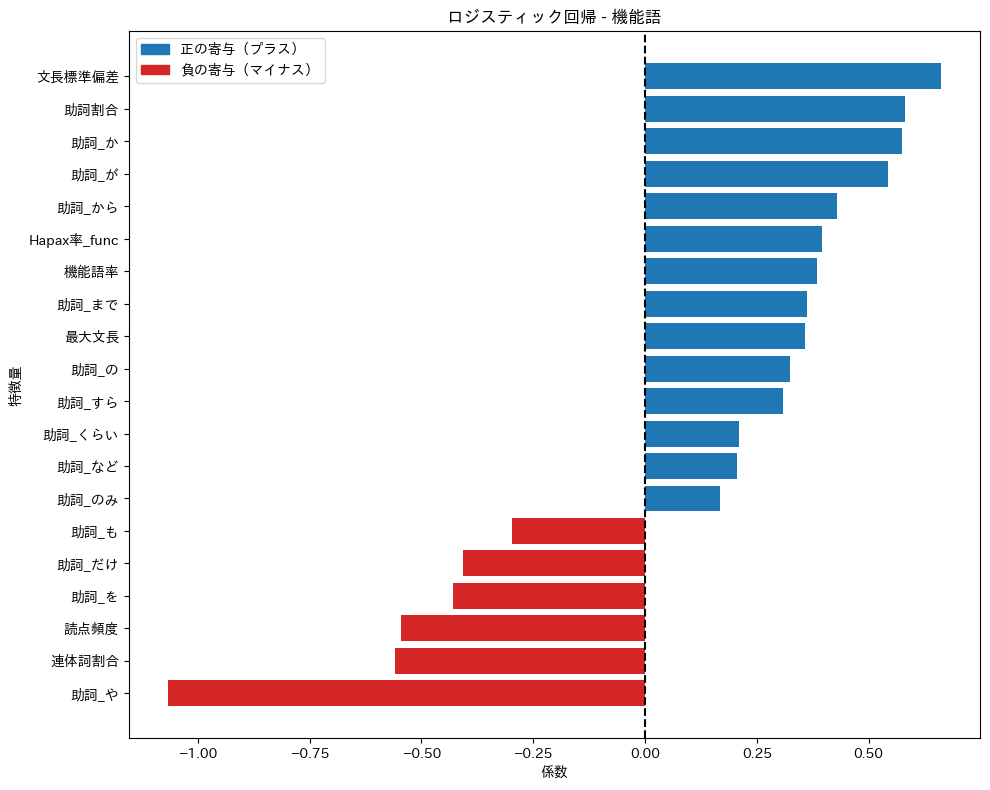

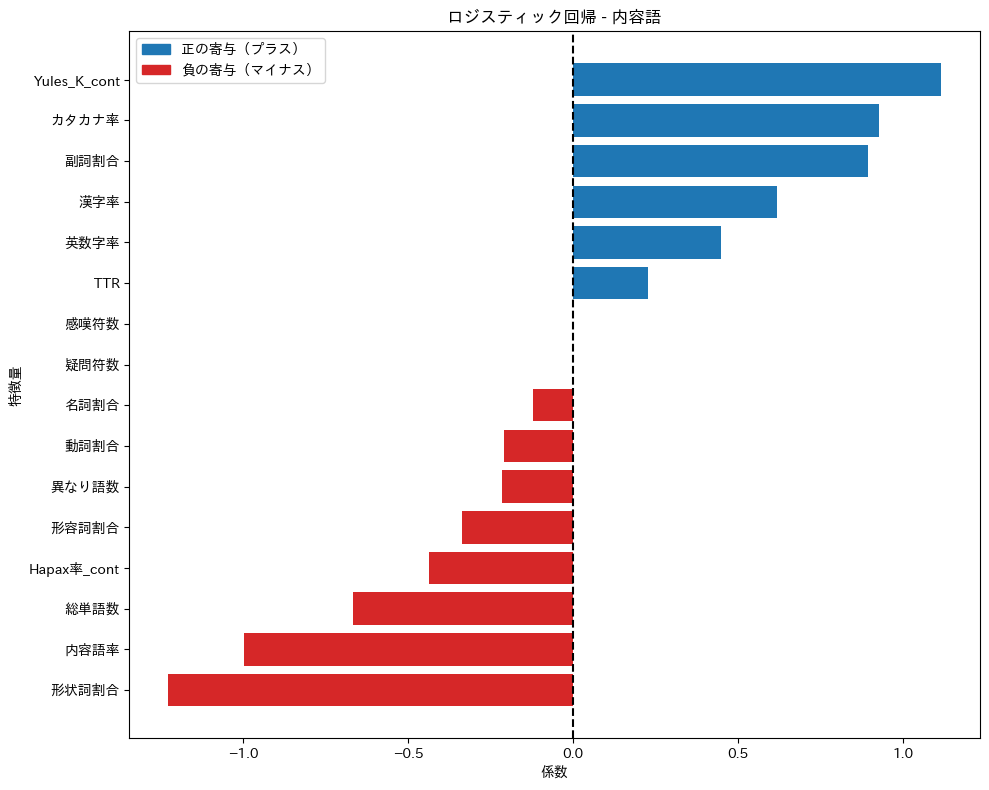

In [17]:
# ===============
# LR：特徴量の方向
# ===============
import pandas as pd
import matplotlib.pyplot as plt
import japanize_matplotlib

files = [
    "coef_abs_All.csv",
    "coef_abs_Function.csv",
    "coef_abs_Content.csv"
]

titles = [
    "ロジスティック回帰 - 特徴量全て",
    "ロジスティック回帰 - 機能語",
    "ロジスティック回帰 - 内容語"
]

for file, title in zip(files, titles):

    df = pd.read_csv(file)

    # 絶対値上位20個
    df = df.reindex(df["coef"].abs().sort_values(ascending=False).index).head(20)

    # 見やすいように並び替え
    df = df.sort_values("coef")

    colors = ["tab:blue" if x > 0 else "tab:red" for x in df["coef"]]

    plt.figure(figsize=(10, 8))

    # 棒グラフを描画
    bars = plt.barh(df["features"], df["coef"], color=colors)
    plt.axvline(0, color="black", linestyle="--")

    # ダミーの描画オブジェクトを作成して凡例を表示する例
    import matplotlib.patches as mpatches

    blue_patch = mpatches.Patch(color="tab:blue", label="正の寄与（プラス）")
    red_patch = mpatches.Patch(color="tab:red", label="負の寄与（マイナス）")
    plt.legend(handles=[blue_patch, red_patch], loc="best")

    plt.title(title)
    plt.xlabel("係数")
    plt.ylabel("特徴量")

    plt.tight_layout()
    plt.savefig(f"{title}.png", dpi=300, bbox_inches="tight")
    plt.show()

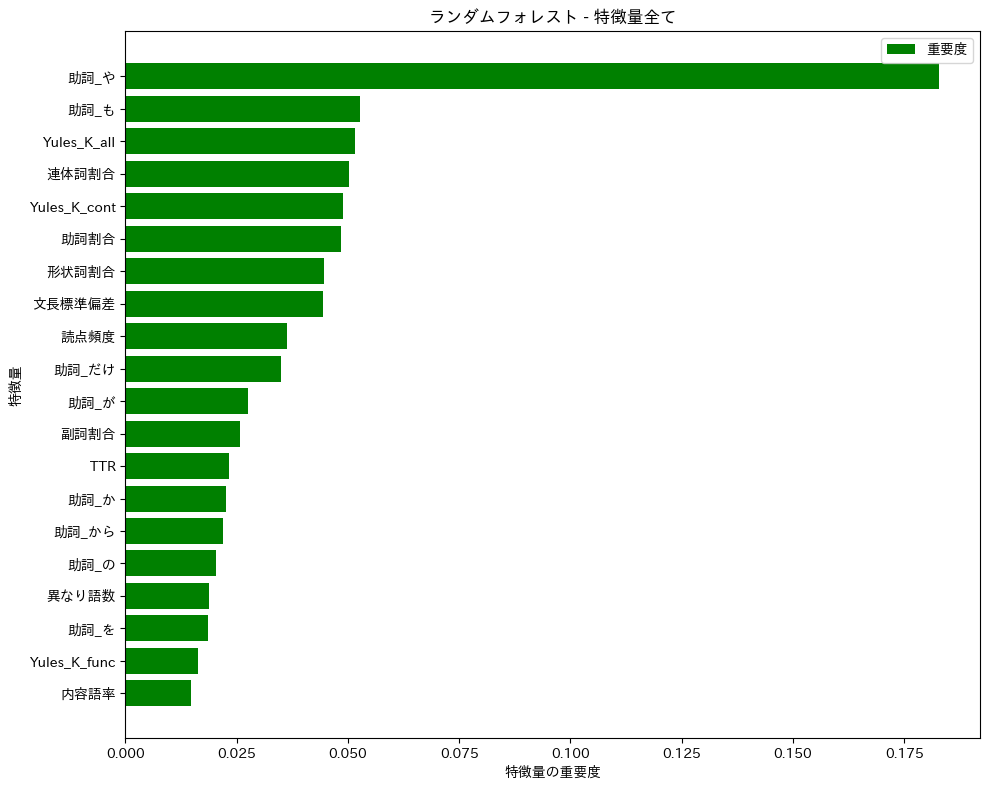

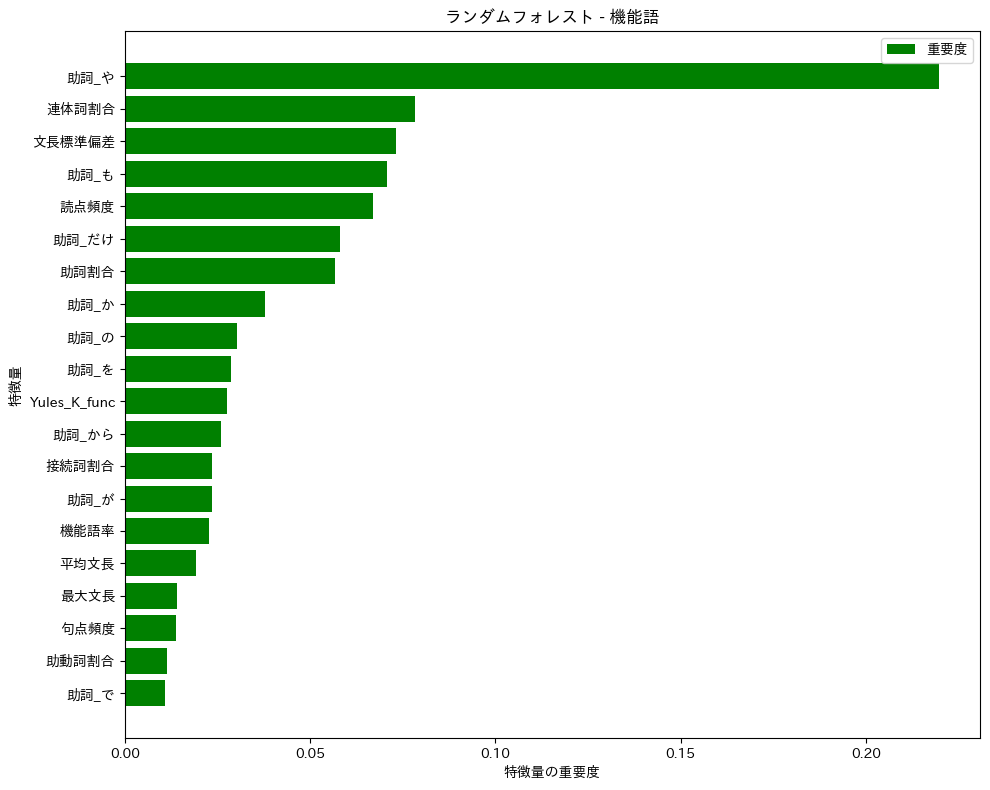

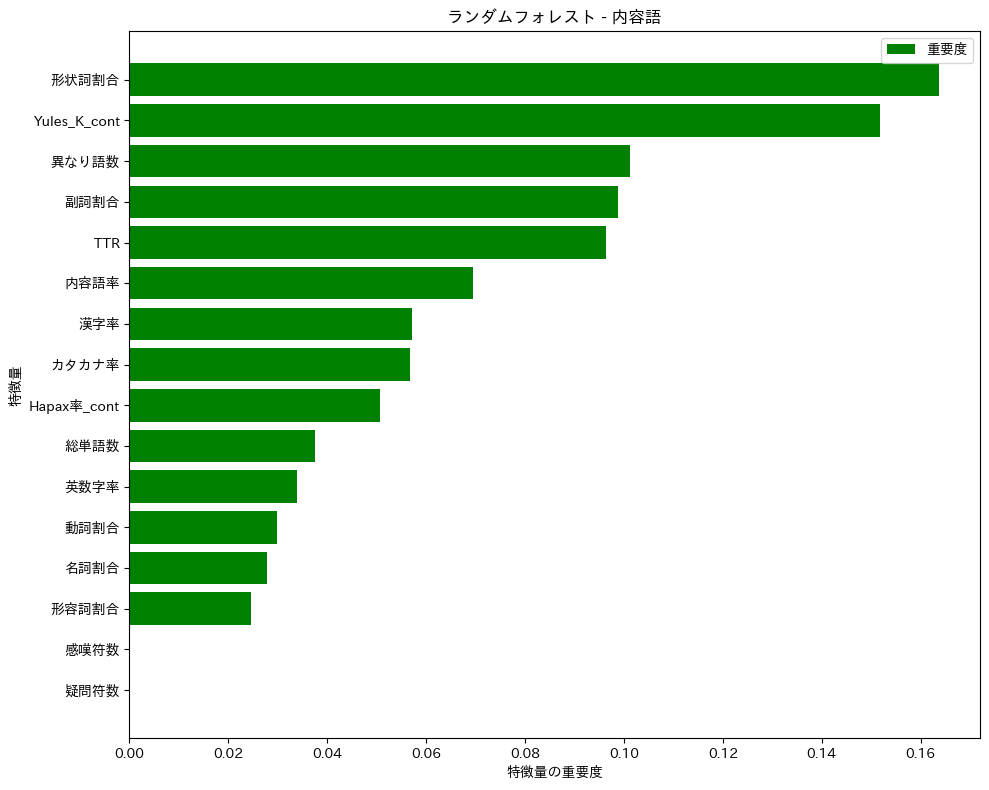

In [16]:
# ===============
# RF：特徴量寄与度
# ===============
import pandas as pd
import matplotlib.pyplot as plt
import japanize_matplotlib

files = ["importance_All.csv", "importance_Function.csv", "importance_Content.csv"]
titles = ["ランダムフォレスト - 特徴量全て", "ランダムフォレスト - 機能語", "ランダムフォレスト - 内容語"]

for file, title in zip(files, titles):
    df = pd.read_csv(file)

    # 上位20個
    df = df.sort_values("importance", ascending=False).head(20)

    # 横棒グラフ用
    df = df.iloc[::-1]

    plt.figure(figsize=(10, 8))

    # label に日本語を指定
    plt.barh(df["features"], df["importance"], color="green", label="重要度")

    plt.title(title)
    plt.xlabel("特徴量の重要度")
    plt.ylabel("特徴量")

    # 凡例を表示
    plt.legend(loc="best")

    plt.tight_layout()
    plt.savefig(f"{title}.png", dpi=300, bbox_inches="tight")
    plt.show()